# VinDr-CXR: Audited Image Preprocessing and Bounding-Box Mask Generation

**Purpose:** create 256×256 grayscale images and five-channel bounding-box-derived pseudo-masks for the selected 300-image subset.

## Important scientific limitations

- VinDr-CXR annotations used here are **bounding boxes**, not pixel-level lesion contours. The generated masks are rectangular pseudo-masks.
- Multiple radiologist boxes for the same finding are combined by **union**. This is not a consensus segmentation.
- The coordinate conversion below assumes `x_min/x_max` are pixel-column coordinates and `y_min/y_max` are pixel-row coordinates in the decoded DICOM pixel array, with origin at the top-left. This notebook checks dimensions and bounds, but cannot prove the source CSV's coordinate convention by itself.
- The image preprocessing is kept consistent with the existing model pipeline: rescale slope/intercept, MONOCHROME1 inversion, 1st–99th percentile clipping, min-max normalization, and bilinear resize to 256×256.
- The current model was trained using the existing `images_256` and `masks_256`. This notebook writes to **new audited output folders** so it does not silently overwrite the training data. Only switch downstream notebooks after the audit and visual overlays have been reviewed.

Run the notebook from the project root or the `notebooks` directory. Execute from top to bottom.

In [23]:
# 1. Imports and reproducibility
from pathlib import Path
from collections import Counter
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pydicom
from PIL import Image

np.set_printoptions(suppress=True)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("pydicom:", pydicom.__version__)
print("Dependencies imported successfully.")

NumPy: 2.5.4
Pandas: 3.0.6
pydicom: 3.0.2
Dependencies imported successfully.


In [24]:
# 2. Resolve project paths robustly
# Works when the notebook is launched from project root or project/notebooks.

cwd = Path.cwd().resolve()
root_candidates = [cwd, *cwd.parents]
ROOT = None

for candidate in root_candidates:
    if (candidate / "data" / "processed").is_dir() and (candidate / "data" / "images").is_dir():
        ROOT = candidate
        break

if ROOT is None:
    raise FileNotFoundError(
        "Could not locate project root. Expected data/processed and data/images "
        "in the current directory or one of its parents."
    )

IMAGE_DIR = ROOT / "data" / "images" / "train" / "vindr_300"
PROCESSED_DIR = ROOT / "data" / "processed"
MANIFEST_PATH = PROCESSED_DIR / "vindr_300_image_manifest.csv"
BBOX_PATH = PROCESSED_DIR / "vindr_300_bounding_boxes.csv"

IMAGE_SIZE = 256
CLASS_NAMES = [
    "Aortic enlargement",
    "Cardiomegaly",
    "Pleural thickening",
    "Pulmonary fibrosis",
    "Lung Opacity",
]
CLASS_TO_INDEX = {name: i for i, name in enumerate(CLASS_NAMES)}

# Safer, versioned destinations. Existing model-training arrays are untouched.
OUTPUT_IMAGE_DIR = PROCESSED_DIR / "images_256_audited"
OUTPUT_MASK_DIR = PROCESSED_DIR / "masks_256_audited"
OUTPUT_IMAGE_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_MASK_DIR.mkdir(parents=True, exist_ok=True)

REPORT_DIR = PROCESSED_DIR / "mask_generation_audit"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("DICOM directory:", IMAGE_DIR)
print("Manifest:", MANIFEST_PATH)
print("Bounding boxes:", BBOX_PATH)
print("Audited image output:", OUTPUT_IMAGE_DIR)
print("Audited mask output:", OUTPUT_MASK_DIR)
print("Class mapping:", CLASS_TO_INDEX)

Project root: C:\Users\johnm\chest-xray-ai-annotation
DICOM directory: C:\Users\johnm\chest-xray-ai-annotation\data\images\train\vindr_300
Manifest: C:\Users\johnm\chest-xray-ai-annotation\data\processed\vindr_300_image_manifest.csv
Bounding boxes: C:\Users\johnm\chest-xray-ai-annotation\data\processed\vindr_300_bounding_boxes.csv
Audited image output: C:\Users\johnm\chest-xray-ai-annotation\data\processed\images_256_audited
Audited mask output: C:\Users\johnm\chest-xray-ai-annotation\data\processed\masks_256_audited
Class mapping: {'Aortic enlargement': 0, 'Cardiomegaly': 1, 'Pleural thickening': 2, 'Pulmonary fibrosis': 3, 'Lung Opacity': 4}


In [25]:
# 3. Load and validate manifest and annotation table
manifest = pd.read_csv(MANIFEST_PATH, dtype={"image_id": "string"})
boxes = pd.read_csv(BBOX_PATH, dtype={"image_id": "string"})

required_manifest = {"image_id"}
required_boxes = {
    "image_id", "class_name", "x_min", "y_min", "x_max", "y_max"
}

missing_manifest = required_manifest - set(manifest.columns)
missing_boxes = required_boxes - set(boxes.columns)
if missing_manifest:
    raise ValueError(f"Manifest missing columns: {sorted(missing_manifest)}")
if missing_boxes:
    raise ValueError(f"Bounding-box CSV missing columns: {sorted(missing_boxes)}")

manifest["image_id"] = manifest["image_id"].astype("string").str.strip()
boxes["image_id"] = boxes["image_id"].astype("string").str.strip()

if manifest["image_id"].isna().any() or (manifest["image_id"] == "").any():
    raise ValueError("Manifest contains empty image IDs.")
if manifest["image_id"].duplicated().any():
    raise ValueError("Manifest contains duplicate image IDs.")

for column in ["x_min", "y_min", "x_max", "y_max"]:
    boxes[column] = pd.to_numeric(boxes[column], errors="coerce")

selected_ids = set(manifest["image_id"].dropna().astype(str))
boxes = boxes[boxes["image_id"].astype(str).isin(selected_ids)].copy()

unknown_classes = sorted(set(boxes["class_name"].dropna()) - set(CLASS_NAMES))
print("Manifest rows:", len(manifest))
print("Unique selected images:", manifest["image_id"].nunique())
print("Selected annotation rows:", len(boxes))
print("Unknown/non-target classes excluded from masks:", unknown_classes)
print("Target box counts:", boxes[boxes["class_name"].isin(CLASS_NAMES)]["class_name"].value_counts())

Manifest rows: 300
Unique selected images: 300
Selected annotation rows: 1799
Unknown/non-target classes excluded from masks: []
Target box counts: class_name
Aortic enlargement    522
Cardiomegaly          379
Pleural thickening    359
Pulmonary fibrosis    337
Lung Opacity          202
Name: count, dtype: int64


In [26]:
# 4. Locate DICOM files reliably (.dicom or .dcm)
def find_dicom(image_id):
    image_id = str(image_id)
    candidates = [IMAGE_DIR / f"{image_id}.dicom", IMAGE_DIR / f"{image_id}.dcm"]
    for path in candidates:
        if path.is_file():
            return path
    raise FileNotFoundError(f"No .dicom or .dcm file found for image_id={image_id}")

missing_files = []
for image_id in manifest["image_id"].astype(str):
    try:
        find_dicom(image_id)
    except FileNotFoundError:
        missing_files.append(image_id)

print("Selected images:", len(manifest))
print("Missing DICOM files:", len(missing_files))
if missing_files:
    print("Examples:", missing_files[:10])
    raise FileNotFoundError("Resolve missing DICOM files before mask generation.")

Selected images: 300
Missing DICOM files: 0


In [27]:
# 5. DICOM preprocessing (kept consistent with the existing training pipeline)
def preprocess_dicom(dicom_path, image_size=IMAGE_SIZE):
    ds = pydicom.dcmread(str(dicom_path))
    image = ds.pixel_array.astype(np.float32)

    if image.ndim != 2:
        raise ValueError(f"Expected 2D DICOM, got {image.shape}: {Path(dicom_path).name}")

    rows = int(getattr(ds, "Rows", image.shape[0]))
    columns = int(getattr(ds, "Columns", image.shape[1]))
    if image.shape != (rows, columns):
        raise ValueError(
            f"Pixel array shape {image.shape} does not match DICOM Rows/Columns "
            f"({rows}, {columns}) for {Path(dicom_path).name}"
        )

    slope = float(getattr(ds, "RescaleSlope", 1.0))
    intercept = float(getattr(ds, "RescaleIntercept", 0.0))
    image = image * slope + intercept

    photometric = str(getattr(ds, "PhotometricInterpretation", ""))
    if photometric == "MONOCHROME1":
        image = image.max() - image
    elif photometric != "MONOCHROME2":
        warnings.warn(f"Unusual PhotometricInterpretation={photometric!r}")

    lower, upper = np.percentile(image, [1, 99])
    if not np.isfinite([lower, upper]).all() or upper <= lower:
        raise ValueError(f"Invalid intensity range in {Path(dicom_path).name}")

    image = np.clip(image, lower, upper)
    image = (image - lower) / (upper - lower)

    pil_image = Image.fromarray(image.astype(np.float32))
    pil_image = pil_image.resize(
        (image_size, image_size),
        resample=Image.Resampling.BILINEAR,
    )
    resized = np.asarray(pil_image, dtype=np.float32)
    resized = np.array(resized, dtype=np.float32, copy=True, order="C")

    if resized.shape != (image_size, image_size):
        raise ValueError(f"Unexpected resized shape: {resized.shape}")
    if not np.isfinite(resized).all():
        raise ValueError("Preprocessed image contains non-finite values.")

    return resized, ds

In [28]:
# 6. Coordinate transformation with clipping and explicit diagnostics
# Assumption: x = pixel column, y = pixel row, origin = top-left;
# coordinates refer to the decoded DICOM pixel array.
def transform_bbox(row, original_width, original_height, image_size=IMAGE_SIZE):
    coords = np.asarray(
        [row["x_min"], row["y_min"], row["x_max"], row["y_max"]],
        dtype=np.float64,
    )
    if not np.isfinite(coords).all():
        return None, "non_finite"

    x0, y0, x1, y1 = coords
    if x1 <= x0 or y1 <= y0:
        return None, "non_positive_area"

    # Clip in the ORIGINAL coordinate system before scaling.
    clipped = np.array([
        np.clip(x0, 0, original_width),
        np.clip(y0, 0, original_height),
        np.clip(x1, 0, original_width),
        np.clip(y1, 0, original_height),
    ], dtype=np.float64)

    cx0, cy0, cx1, cy1 = clipped
    if cx1 <= cx0 or cy1 <= cy0:
        return None, "outside_image"

    was_clipped = not np.allclose(coords, clipped)

    sx = image_size / float(original_width)
    sy = image_size / float(original_height)

    # Half-open array coordinates [x0:x1, y0:y1].
    ix0 = int(np.floor(cx0 * sx))
    iy0 = int(np.floor(cy0 * sy))
    ix1 = int(np.ceil(cx1 * sx))
    iy1 = int(np.ceil(cy1 * sy))

    ix0 = int(np.clip(ix0, 0, image_size))
    iy0 = int(np.clip(iy0, 0, image_size))
    ix1 = int(np.clip(ix1, 0, image_size))
    iy1 = int(np.clip(iy1, 0, image_size))

    if ix1 <= ix0 or iy1 <= iy0:
        return None, "collapsed_after_resize"

    return (ix0, iy0, ix1, iy1), ("clipped" if was_clipped else "valid")

Sample ID: 690a74b4ebf969fbadc5ad0a1187968d
Decoded array shape: (2712, 2626)
DICOM Rows/Columns: 2712 2626
Photometric: MONOCHROME2
Target annotation rows: 10


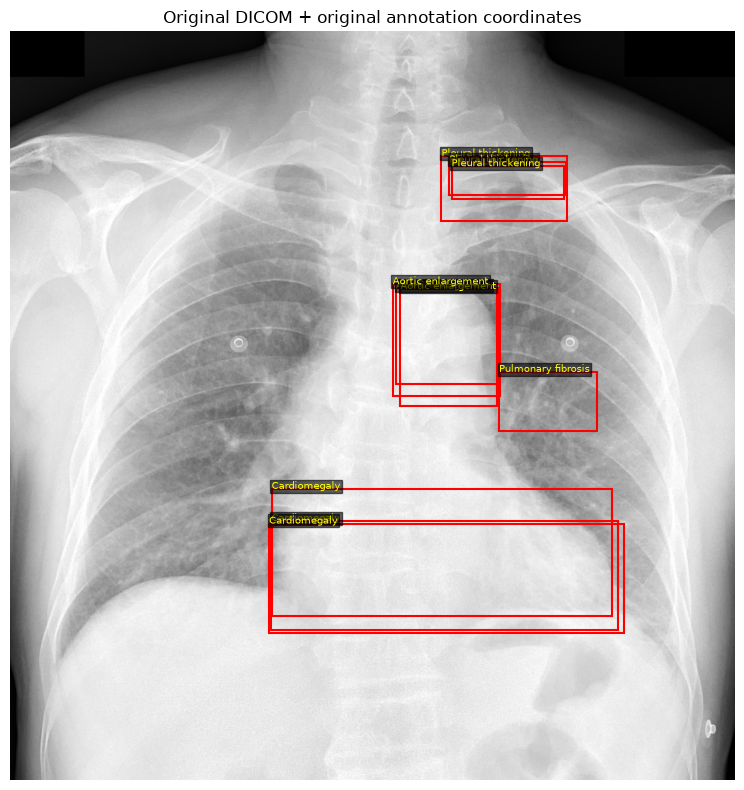

NOTE: This overlay is the essential visual check of source-coordinate alignment.


In [29]:
# 7. Inspect one selected image and its original-coordinate annotations
sample_id = str(manifest.iloc[0]["image_id"])
sample_path = find_dicom(sample_id)
sample_image, sample_ds = preprocess_dicom(sample_path)
sample_h, sample_w = sample_ds.pixel_array.shape

sample_boxes = boxes[
    (boxes["image_id"].astype(str) == sample_id)
    & (boxes["class_name"].isin(CLASS_NAMES))
].copy()

print("Sample ID:", sample_id)
print("Decoded array shape:", sample_ds.pixel_array.shape)
print("DICOM Rows/Columns:", sample_ds.Rows, sample_ds.Columns)
print("Photometric:", getattr(sample_ds, "PhotometricInterpretation", "unknown"))
print("Target annotation rows:", len(sample_boxes))

fig, ax = plt.subplots(figsize=(8, 8))
# Display original pixel array. Intensity windowing here is for visualization only.
original = sample_ds.pixel_array.astype(np.float32)
lo, hi = np.percentile(original, [1, 99])
ax.imshow(np.clip(original, lo, hi), cmap="gray")
for _, b in sample_boxes.iterrows():
    x0, y0, x1, y1 = [float(b[k]) for k in ["x_min", "y_min", "x_max", "y_max"]]
    ax.add_patch(plt.Rectangle((x0, y0), x1-x0, y1-y0, fill=False, edgecolor="red", linewidth=1.5))
    ax.text(x0, y0, str(b["class_name"]), color="yellow", fontsize=7,
            bbox={"facecolor": "black", "alpha": 0.6, "pad": 1})
ax.set_title("Original DICOM + original annotation coordinates")
ax.axis("off")
plt.tight_layout()
plt.show()

print("NOTE: This overlay is the essential visual check of source-coordinate alignment.")

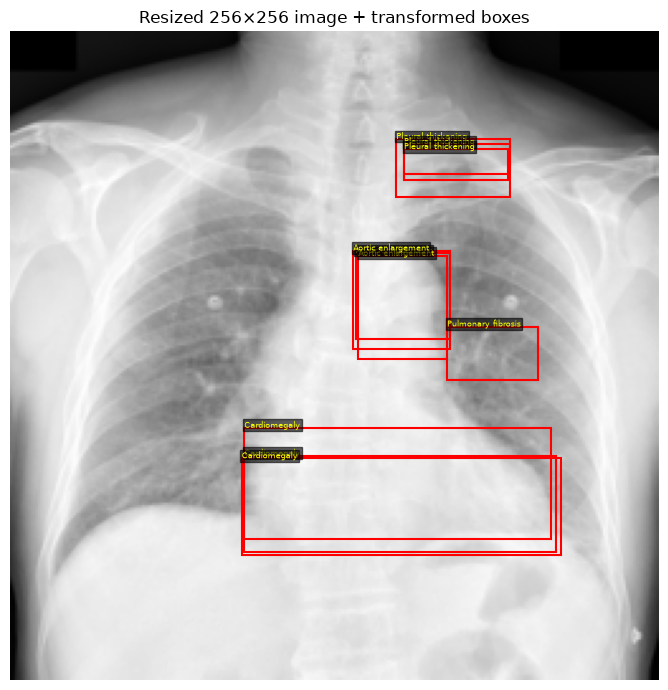

,class_name,rad_id,x0,y0,x1,y1,status
0,Aortic enlargement,R10,136,87,173,121,valid
1,Aortic enlargement,R8,137,88,172,129,valid
2,Aortic enlargement,R9,135,86,173,125,valid
3,Cardiomegaly,R10,92,167,215,205,valid
4,Cardiomegaly,R8,92,156,213,200,valid
5,Cardiomegaly,R9,91,168,217,206,valid
6,Pleural thickening,R10,152,42,197,65,valid
7,Pleural thickening,R8,155,44,197,56,valid
8,Pleural thickening,R9,155,46,196,58,valid
9,Pulmonary fibrosis,R9,172,116,208,137,valid


In [30]:
# 8. Inspect transformed boxes on the exact resized image used by preprocessing
fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(sample_image, cmap="gray", vmin=0, vmax=1)
transformed_records = []
for _, b in sample_boxes.iterrows():
    box, status = transform_bbox(b, sample_w, sample_h)
    if box is None:
        print("Rejected box:", b.get("class_name"), status)
        continue
    x0, y0, x1, y1 = box
    ax.add_patch(plt.Rectangle((x0, y0), x1-x0, y1-y0,
                               fill=False, edgecolor="red", linewidth=1.5))
    ax.text(x0, y0, str(b["class_name"]), color="yellow", fontsize=6,
            bbox={"facecolor": "black", "alpha": 0.6, "pad": 1})
    transformed_records.append({"class_name": b["class_name"], "rad_id": b.get("rad_id"),
                                "x0": x0, "y0": y0, "x1": x1, "y1": y1,
                                "status": status})
ax.set_title("Resized 256×256 image + transformed boxes")
ax.axis("off")
plt.tight_layout()
plt.show()
display(pd.DataFrame(transformed_records))

Sample transform statuses: {'valid': 10}
Aortic enlargement: 1,622 mask pixels
Cardiomegaly: 6,242 mask pixels
Pleural thickening: 1,035 mask pixels
Pulmonary fibrosis: 756 mask pixels
Lung Opacity: 0 mask pixels


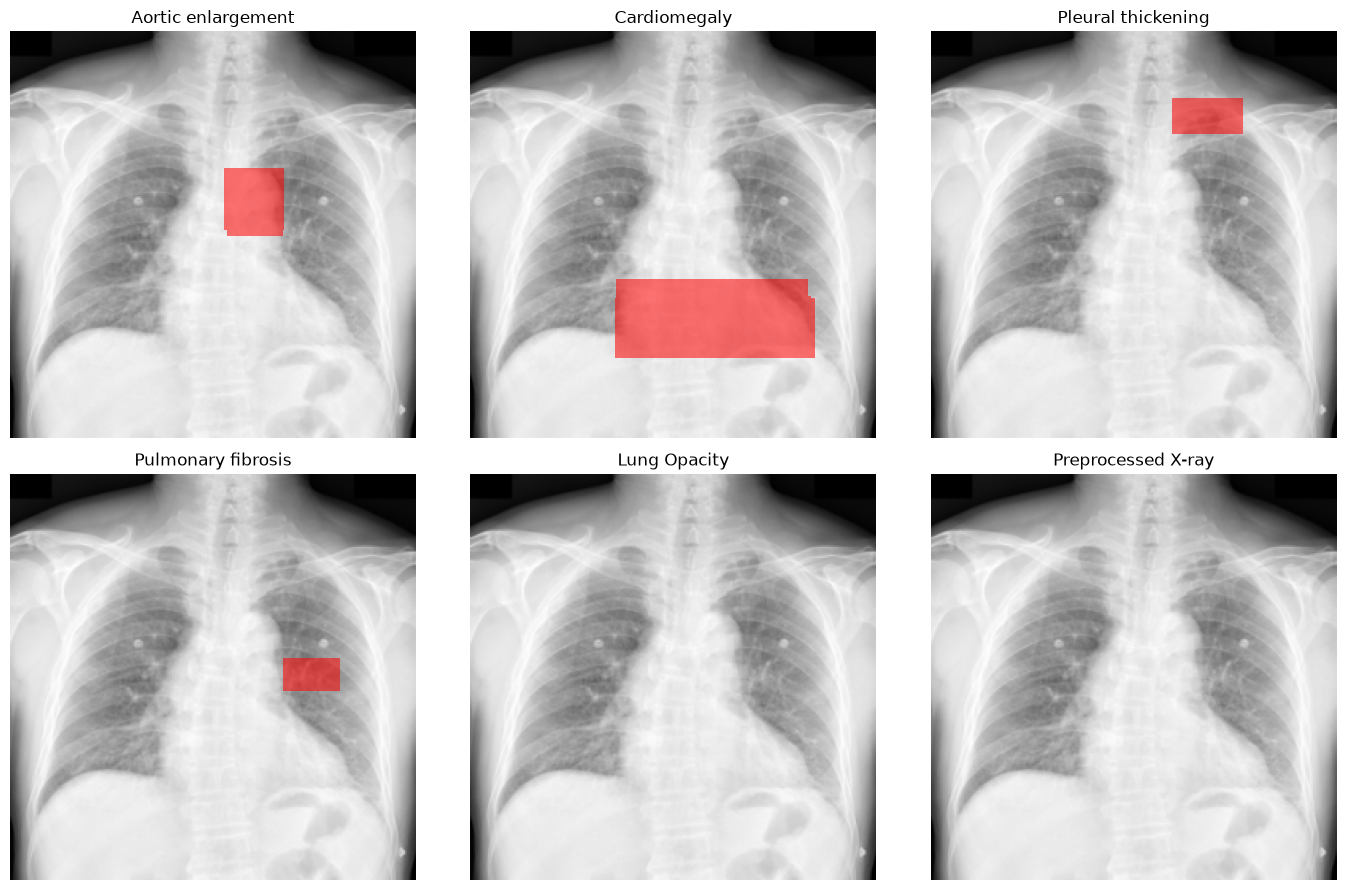

In [31]:
# 9. Generate a sample five-channel pseudo-mask and inspect overlays
sample_mask = np.zeros((IMAGE_SIZE, IMAGE_SIZE, len(CLASS_NAMES)), dtype=np.uint8)
sample_statuses = Counter()
for _, b in sample_boxes.iterrows():
    channel = CLASS_TO_INDEX[b["class_name"]]
    box, status = transform_bbox(b, sample_w, sample_h)
    sample_statuses[status] += 1
    if box is None:
        continue
    x0, y0, x1, y1 = box
    sample_mask[y0:y1, x0:x1, channel] = 1

print("Sample transform statuses:", dict(sample_statuses))
for name, channel in CLASS_TO_INDEX.items():
    print(f"{name}: {int(sample_mask[:, :, channel].sum()):,} mask pixels")

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for name, channel in CLASS_TO_INDEX.items():
    ax = axes.flat[channel]
    ax.imshow(sample_image, cmap="gray", vmin=0, vmax=1)
    overlay = np.ma.masked_where(sample_mask[:, :, channel] == 0,
                                 sample_mask[:, :, channel])
    ax.imshow(overlay, cmap="autumn", alpha=0.55, interpolation="nearest")
    ax.set_title(name)
    ax.axis("off")
axes.flat[5].imshow(sample_image, cmap="gray", vmin=0, vmax=1)
axes.flat[5].set_title("Preprocessed X-ray")
axes.flat[5].axis("off")
plt.tight_layout()
plt.show()

## Full dataset generation

The next cell writes to `images_256_audited/` and `masks_256_audited/`. It does **not** overwrite the existing training arrays. Each annotation is checked, clipped only when it partially intersects the image, and logged. Boxes outside the image or invalid boxes are rejected and recorded rather than silently converted into one-pixel masks.

In [32]:
# 10. Build per-image annotation groups and generate all selected arrays
bbox_groups = {
    str(image_id): group.copy()
    for image_id, group in boxes[boxes["class_name"].isin(CLASS_NAMES)].groupby("image_id")
}

processing_results = []
box_audit_rows = []
processing_errors = []

for idx, manifest_row in manifest.iterrows():
    image_id = str(manifest_row["image_id"])
    dicom_path = find_dicom(image_id)

    try:
        image, ds = preprocess_dicom(dicom_path)
        original_height, original_width = ds.pixel_array.shape
        mask = np.zeros((IMAGE_SIZE, IMAGE_SIZE, len(CLASS_NAMES)), dtype=np.uint8)
        image_boxes = bbox_groups.get(image_id, pd.DataFrame())
        status_counts = Counter()

        for box_index, b in image_boxes.iterrows():
            transformed, status = transform_bbox(b, original_width, original_height)
            status_counts[status] += 1
            record = {
                "image_id": image_id,
                "source_row_index": int(box_index),
                "class_name": b["class_name"],
                "rad_id": b.get("rad_id", np.nan),
                "transform_status": status,
                "original_width": original_width,
                "original_height": original_height,
            }
            if transformed is not None:
                x0, y0, x1, y1 = transformed
                channel = CLASS_TO_INDEX[b["class_name"]]
                mask[y0:y1, x0:x1, channel] = 1
                record.update({"x0_256": x0, "y0_256": y0, "x1_256": x1, "y1_256": y1})
            else:
                record.update({"x0_256": np.nan, "y0_256": np.nan,
                               "x1_256": np.nan, "y1_256": np.nan})
            box_audit_rows.append(record)

        # Ensure values and shapes are valid before saving.
        assert image.shape == (IMAGE_SIZE, IMAGE_SIZE)
        assert mask.shape == (IMAGE_SIZE, IMAGE_SIZE, len(CLASS_NAMES))
        assert image.dtype == np.float32 and mask.dtype == np.uint8
        assert np.isfinite(image).all()
        assert set(np.unique(mask)).issubset({0, 1})

        np.save(OUTPUT_IMAGE_DIR / f"{image_id}.npy", image)
        np.save(OUTPUT_MASK_DIR / f"{image_id}.npy", mask)

        result = {
            "image_id": image_id,
            "original_height": original_height,
            "original_width": original_width,
            "image_shape": str(image.shape),
            "mask_shape": str(mask.shape),
            "bbox_rows": len(image_boxes),
            "valid_boxes": status_counts["valid"],
            "clipped_boxes": status_counts["clipped"],
            "rejected_non_finite": status_counts["non_finite"],
            "rejected_non_positive_area": status_counts["non_positive_area"],
            "rejected_outside_image": status_counts["outside_image"],
            "rejected_collapsed_after_resize": status_counts["collapsed_after_resize"],
        }
        for class_name, channel in CLASS_TO_INDEX.items():
            result[f"pixels_{class_name}"] = int(mask[:, :, channel].sum())
        processing_results.append(result)

        if len(processing_results) % 25 == 0:
            print(f"Processed {len(processing_results)}/{len(manifest)} images")

    except Exception as exc:
        processing_errors.append({"image_id": image_id, "error": repr(exc)})
        print(f"FAILED {image_id}: {exc}")

print("Generation complete")
print("Successful images:", len(processing_results))
print("Failed images:", len(processing_errors))

Processed 25/300 images
Processed 50/300 images
Processed 75/300 images
Processed 100/300 images
Processed 125/300 images
Processed 150/300 images
Processed 175/300 images
Processed 200/300 images
Processed 225/300 images
Processed 250/300 images
Processed 275/300 images
Processed 300/300 images
Generation complete
Successful images: 300
Failed images: 0


In [33]:
# 11. Save audit reports
processing_df = pd.DataFrame(processing_results)
box_audit_df = pd.DataFrame(box_audit_rows)
errors_df = pd.DataFrame(processing_errors, columns=["image_id", "error"])

processing_report = REPORT_DIR / "image_mask_generation_report.csv"
box_report = REPORT_DIR / "bounding_box_transform_audit.csv"
error_report = REPORT_DIR / "processing_errors.csv"

processing_df.to_csv(processing_report, index=False)
box_audit_df.to_csv(box_report, index=False)
errors_df.to_csv(error_report, index=False)

print("Saved:", processing_report)
print("Saved:", box_report)
print("Saved:", error_report)
print("Total transformed box records:", len(box_audit_df))
if not box_audit_df.empty:
    print("Transform status counts:", box_audit_df["transform_status"].value_counts(dropna=False))

Saved: C:\Users\johnm\chest-xray-ai-annotation\data\processed\mask_generation_audit\image_mask_generation_report.csv
Saved: C:\Users\johnm\chest-xray-ai-annotation\data\processed\mask_generation_audit\bounding_box_transform_audit.csv
Saved: C:\Users\johnm\chest-xray-ai-annotation\data\processed\mask_generation_audit\processing_errors.csv
Total transformed box records: 1799
Transform status counts: transform_status
valid    1799
Name: count, dtype: int64


In [34]:
# 12. Validate every generated image-mask pair
saved_images = {p.stem for p in OUTPUT_IMAGE_DIR.glob("*.npy")}
saved_masks = {p.stem for p in OUTPUT_MASK_DIR.glob("*.npy")}
expected_ids = set(manifest["image_id"].astype(str))

print("Expected IDs:", len(expected_ids))
print("Saved image arrays:", len(saved_images))
print("Saved mask arrays:", len(saved_masks))
print("Missing image arrays:", len(expected_ids - saved_images))
print("Missing mask arrays:", len(expected_ids - saved_masks))
print("Unexpected image arrays:", len(saved_images - expected_ids))
print("Unexpected mask arrays:", len(saved_masks - expected_ids))

validation_errors = []
for image_id in sorted(expected_ids & saved_images & saved_masks):
    try:
        image = np.load(OUTPUT_IMAGE_DIR / f"{image_id}.npy")
        mask = np.load(OUTPUT_MASK_DIR / f"{image_id}.npy")
        if image.shape != (IMAGE_SIZE, IMAGE_SIZE):
            raise ValueError(f"bad image shape {image.shape}")
        if mask.shape != (IMAGE_SIZE, IMAGE_SIZE, len(CLASS_NAMES)):
            raise ValueError(f"bad mask shape {mask.shape}")
        if image.dtype != np.float32 or mask.dtype != np.uint8:
            raise ValueError(f"bad dtypes {image.dtype}, {mask.dtype}")
        if not np.isfinite(image).all():
            raise ValueError("non-finite image values")
        if image.min() < 0 or image.max() > 1:
            raise ValueError("image intensity outside [0,1]")
        if not set(np.unique(mask)).issubset({0, 1}):
            raise ValueError(f"unexpected mask values {np.unique(mask)}")
    except Exception as exc:
        validation_errors.append({"image_id": image_id, "error": repr(exc)})

validation_df = pd.DataFrame(validation_errors)
validation_path = REPORT_DIR / "array_validation_errors.csv"
validation_df.to_csv(validation_path, index=False)

print("Pair validation errors:", len(validation_errors))
print("Validation report:", validation_path)

if missing_images := expected_ids - saved_images:
    print("WARNING: some images were not generated.")
if missing_masks := expected_ids - saved_masks:
    print("WARNING: some masks were not generated.")
if validation_errors:
    display(validation_df.head(20))

Expected IDs: 300
Saved image arrays: 300
Saved mask arrays: 300
Missing image arrays: 0
Missing mask arrays: 0
Unexpected image arrays: 0
Unexpected mask arrays: 0
Pair validation errors: 0
Validation report: C:\Users\johnm\chest-xray-ai-annotation\data\processed\mask_generation_audit\array_validation_errors.csv


In [35]:
# 13. Compare image-level positive labels with generated mask presence
# This checks internal consistency only. It does not establish clinical absence/presence.
label_columns = [c for c in CLASS_NAMES if c in manifest.columns]
consistency_rows = []

for _, r in manifest.iterrows():
    image_id = str(r["image_id"])
    mask_path = OUTPUT_MASK_DIR / f"{image_id}.npy"
    if not mask_path.exists():
        continue
    mask = np.load(mask_path)
    for class_name, channel in CLASS_TO_INDEX.items():
        mask_present = bool(mask[:, :, channel].any())
        label_present = np.nan
        if class_name in label_columns:
            label_present = bool(pd.to_numeric(pd.Series([r[class_name]]), errors="coerce").fillna(0).iloc[0] > 0)
        consistency_rows.append({
            "image_id": image_id,
            "class_name": class_name,
            "image_level_label_present": label_present,
            "bbox_mask_present": mask_present,
            "mismatch": (label_present != mask_present) if pd.notna(label_present) else np.nan,
        })

consistency_df = pd.DataFrame(consistency_rows)
consistency_path = REPORT_DIR / "label_mask_consistency.csv"
consistency_df.to_csv(consistency_path, index=False)
print("Saved:", consistency_path)
if "mismatch" in consistency_df and consistency_df["mismatch"].notna().any():
    print("Label/mask mismatches:", int(consistency_df["mismatch"].sum()))
    display(consistency_df[consistency_df["mismatch"]].head(20))
else:
    print("No comparable image-level label columns found, or no rows to compare.")

Saved: C:\Users\johnm\chest-xray-ai-annotation\data\processed\mask_generation_audit\label_mask_consistency.csv
Label/mask mismatches: 0


,image_id,class_name,image_level_label_present,bbox_mask_present,mismatch


In [36]:
# 14. Final summary by finding
if not processing_df.empty:
    summary_rows = []
    for class_name in CLASS_NAMES:
        pixel_col = f"pixels_{class_name}"
        summary_rows.append({
            "class_name": class_name,
            "images_with_nonempty_mask": int((processing_df[pixel_col] > 0).sum()),
            "total_mask_pixels": int(processing_df[pixel_col].sum()),
        })
    summary_df = pd.DataFrame(summary_rows)
    summary_path = REPORT_DIR / "class_mask_summary.csv"
    summary_df.to_csv(summary_path, index=False)
    display(summary_df)
    print("Saved:", summary_path)

print("AUDITED OUTPUT DIRECTORIES")
print("Images:", OUTPUT_IMAGE_DIR)
print("Masks:", OUTPUT_MASK_DIR)
print("Reports:", REPORT_DIR)
print("Do not replace the original training arrays until the source-coordinate convention and visual overlays have been reviewed.")

,class_name,images_with_nonempty_mask,total_mask_pixels
0,Aortic enlargement,218,279825
1,Cardiomegaly,163,795245
2,Pleural thickening,146,154131
3,Pulmonary fibrosis,123,288035
4,Lung Opacity,108,403962


Saved: C:\Users\johnm\chest-xray-ai-annotation\data\processed\mask_generation_audit\class_mask_summary.csv
AUDITED OUTPUT DIRECTORIES
Images: C:\Users\johnm\chest-xray-ai-annotation\data\processed\images_256_audited
Masks: C:\Users\johnm\chest-xray-ai-annotation\data\processed\masks_256_audited
Reports: C:\Users\johnm\chest-xray-ai-annotation\data\processed\mask_generation_audit
Do not replace the original training arrays until the source-coordinate convention and visual overlays have been reviewed.
